# Détectez des faux billets utilisant le algorithme de regression logistique

In [17]:
# Importer les bibliothèques nécessaires
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


In [18]:
# Charger les données à prédire
DATA_PATH = "Donnees_predire/billets_production.csv"

if not os.path.exists(DATA_PATH):
    print(f"❌ Attention : le fichier '{DATA_PATH}' n'existe pas.")

try:
    df_predire = pd.read_csv(DATA_PATH, sep=",")
    print("✅ Données chargées :", df_predire.shape)
    display(df_predire.head())
except Exception as e:
    print("❌ Erreur lors du chargement :", e)

✅ Données chargées : (5, 7)


,diagonal,height_left,height_right,margin_low,margin_up,length,id
0,171.76,104.01,103.54,5.21,3.30,111.42,A_1
1,171.87,104.17,104.13,6.00,3.31,112.09,A_2
2,172.00,104.58,104.29,4.99,3.39,111.57,A_3
3,172.49,104.55,104.34,4.44,3.03,113.20,A_4
4,171.65,103.63,103.56,3.77,3.16,113.33,A_5


In [19]:
# Definir le feature de la target
id_col = df_predire["id"]
X_unknown = df_predire.drop(columns="id")
#print("Données à prédire :")
#X_unknown

In [20]:
# Charger le modéle KNN sauvgardé avec joblib
pipe_knn = joblib.load("Donnees_resultats/model_billet_fraud_knn.pkl")

# Predire les classes en utilisant le meilleur seuil de classification pour maximiser le Recall
best_threshold_knn = 0.31   ## NOTE CHANGE THRESHOLD!
y_proba_knn = pipe_knn.predict_proba(X_unknown)[:,1]

is_fake_pred = (y_proba_knn >= best_threshold_knn).astype(int)
print("Resultat : vector de prédictions (1 = faux billet, 0 = vrai billet) :")
print(is_fake_pred)
 
df_predire["is_Fake"] = is_fake_pred
print("\nResultat: données avec prédictions")
df_predire

Resultat : vector de prédictions (1 = faux billet, 0 = vrai billet) :
[1 1 1 0 0]

Resultat: données avec prédictions


,diagonal,height_left,height_right,margin_low,margin_up,length,id,is_Fake
0,171.76,104.01,103.54,5.21,3.30,111.42,A_1,1
1,171.87,104.17,104.13,6.00,3.31,112.09,A_2,1
2,172.00,104.58,104.29,4.99,3.39,111.57,A_3,1
3,172.49,104.55,104.34,4.44,3.03,113.20,A_4,0
4,171.65,103.63,103.56,3.77,3.16,113.33,A_5,0


In [21]:
# Charger le modéle regression logistique sauvgardé avec joblib
pipe_lr = joblib.load("Donnees_resultats/model_billet_fraud_lr.pkl")

# Predire les classes en utilisant le meilleur seuil de classification pour maximiser le Recall
best_threshold_lr = 0.31
y_proba_lr = pipe_lr.predict_proba(X_unknown)[:,1]

is_fake_pred = (y_proba_lr >= best_threshold_lr).astype(int)
is_fake_pred
print("Resultat : vector de prédictions (1 = faux billet, 0 = vrai billet) :")
print(is_fake_pred)

df_predire["is_Fake"] = is_fake_pred
print("\nResultat: données avec prédictions")
df_predire

Resultat : vector de prédictions (1 = faux billet, 0 = vrai billet) :
[1 1 1 0 0]

Resultat: données avec prédictions


,diagonal,height_left,height_right,margin_low,margin_up,length,id,is_Fake
0,171.76,104.01,103.54,5.21,3.30,111.42,A_1,1
1,171.87,104.17,104.13,6.00,3.31,112.09,A_2,1
2,172.00,104.58,104.29,4.99,3.39,111.57,A_3,1
3,172.49,104.55,104.34,4.44,3.03,113.20,A_4,0
4,171.65,103.63,103.56,3.77,3.16,113.33,A_5,0


# Visualisation

Représentez graphiquement les valeurs prédites avec leur identifiant, en les comparant aux données d'entraînement projetés avec PCA

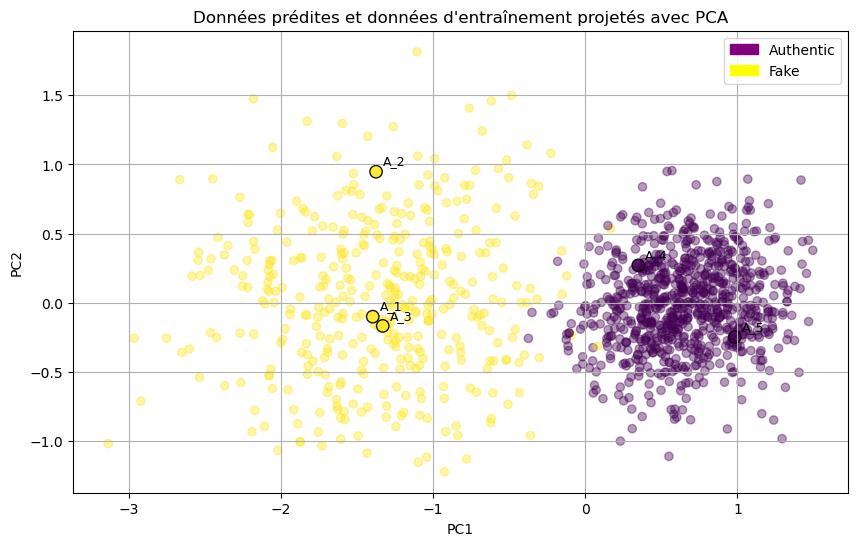

In [22]:
# Visualiser les clusters K-means et ces centroids avec PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import matplotlib.patches as mpatches

# Charger les données d'entraînement utilisées pour le regression logistique (et knn)
X_train, X_test = joblib.load("Donnees_resultats/X_train_test_raw_data_knn.pkl")

# Fit PCA sur les données d'entraînement 
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_unknown_pca = pca.transform(X_unknown)

# Prédire clusters
train_labels = pipe_lr.predict(X_train)
unknown_labels = is_fake_pred

plt.figure(figsize=(10,6))

# Données d'entraînement
plt.scatter(
    X_train_pca[:,0], X_train_pca[:,1],
    c=train_labels,
    cmap='viridis',
    alpha=0.4,
    label='Train'
)

# Données inconnues
plt.scatter(
    X_unknown_pca[:,0], X_unknown_pca[:,1],
    c=unknown_labels,
    cmap='viridis',
    alpha=0.9,
    marker='o',
    s = 80,
    edgecolor='black',
    label='Unknown'
)

# ➤ Ajouter les ID labels pour les points inconnus
for i, txt in enumerate(id_col):
    plt.annotate(
        txt,
        (X_unknown_pca[i,0], X_unknown_pca[i,1]),
        textcoords="offset points",
        xytext=(5,5),
        fontsize=9
    )

# Légende personnalisée
purple_patch = mpatches.Patch(color='purple', label='Authentic')
yellow_patch = mpatches.Patch(color='yellow', label='Fake')
plt.legend(handles=[purple_patch, yellow_patch])

plt.title("Données prédites et données d'entraînement projetés avec PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()


Représentez graphiquement les valeurs prédites avec leur identifiant, en les comparant aux données d'entraînement et aux deux variables prédictives les plus performantes.

In [23]:
# Telecharger les "training data" pour visualiser les resultats de la prediction
DATA_PATH = "Donnees_resultats/df_complete.csv"

if not os.path.exists(DATA_PATH):
    print(f"❌ Attention : le fichier '{DATA_PATH}' n'existe pas.")

try:
    df = pd.read_csv(DATA_PATH, sep=";", header=0)
    print("✅ Données chargées :", df.shape)
    #display(df.head())
except Exception as e:
    print("❌ Erreur lors du chargement :", e)


✅ Données chargées : (1500, 8)


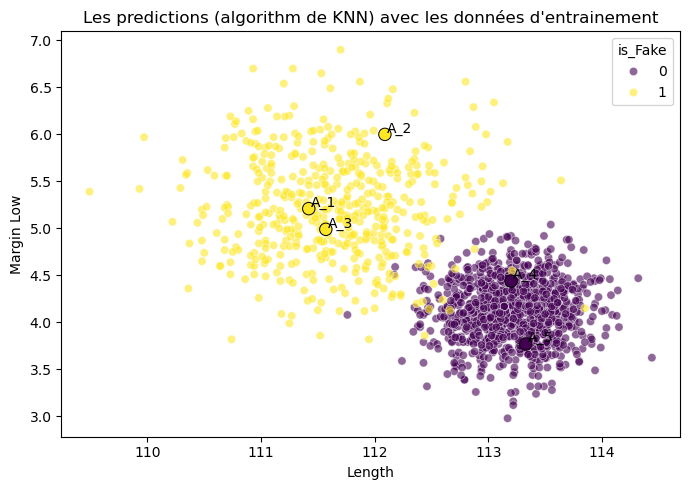

In [24]:
# Visualier les prediction des données inconnue avec les données d'entrainement, et avec les deux variables les plus explicatives: "length" et "margin_low"
# Graphique
plt.figure(figsize=(7, 5))

# Palette de coleur fake/authentic
colors = {1: (0.993248, 0.906157, 0.143936, 1.0), 
          0: (0.267004, 0.004874, 0.329415, 1.0)}

# Scatterplot principale pour df
sns.scatterplot(
    data=df,
    x='length',
    y='margin_low',
    hue='is_Fake',
    palette=colors,
    alpha=0.6
)

# Scatterplot pour données inconnue, df_test
sns.scatterplot(
    data=df_predire,
    x='length',
    y='margin_low',
    hue='is_Fake',
    palette=colors,
    legend=False,     
    s=80,            
    edgecolor='black'
)

# Ajouter un ID pour les points inconnue
for _, row in df_predire.iterrows():
    plt.text(
        row['length'] + 0.02,     # offset horizontal
        row['margin_low'] + 0.02, # offset vertical
        str(row['id']),
        fontsize=10,
        color='black'
    )

plt.title("Les predictions (algorithm de KNN) avec les données d'entrainement")
plt.xlabel('Length')
plt.ylabel('Margin Low')
plt.legend(title="is_Fake")
plt.tight_layout()
plt.show()
